# R6 · Exponentielle et logarithmes — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r6_exp_log/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R6.1 à R6.8, R6.11, R6.12 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R6.14 | Un logarithme dans n'importe quelle base · `log_base` | 🔨 | ★ | 15 |
|  | R6.15 | Sigmoïde et tanh à partir de exp · `sigmoid`, `tanh` | 🔨 | ★★ | 20 |
|  | R6.16 | Temps de doublement · `doubling_time` | 🔨 | ★ | 15 |
| B | R6.17 | Sur tout un tableau : `np.exp`, `np.log2` et `scipy.special.expit` | 📦 | ★ | 15 |
|  | R6.18 | Prédire : exp(800) avec math et NumPy, et le produit de 600 probabilités de 0,25 | 🔮 | ★★ | 15 |
|  | R6.19 | Croissances comparées : x¹⁰, 2ˣ et ln x de plus en plus loin | 🔬 | ★★ | 20 |
|  | R6.20 | Les mêmes données en échelle linéaire et en échelle logarithmique | 🎨 | ★ | 15 |
| C | R6.21 | Chasse à l'erreur : ln(a + b), e^(a + b) et log(0) | 🐛 | ★★ | 15 |
|  | R6.22 | Lire la documentation de `numpy.log`, `log2`, `log10`, `log1p` | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : propriétés de exp et de ln, équations, changements de base, bits et nats, doublements, sigmoïde et logit, échelles logarithmiques, log-probabilités.
- Écrire les quatre fonctions de `mymath/explog.py` et les tester.
- Calculer sur des tableaux avec NumPy, comparer des croissances par leurs logarithmes, tracer une échelle logarithmique, chasser des règles mal appliquées et lire une documentation.

**Rappel express.** $e^{a+b} = e^a e^b$, $(e^a)^b = e^{ab}$, $e^x > 0$. $\ln$ est la réciproque de exp : $\ln(e^y) = y$, $e^{\ln x} = x$ pour $x > 0$. $\ln(ab) = \ln a + \ln b$, $\ln(a^k) = k \ln a$ ; $\ln(a + b)$ ne se simplifie pas. $\log_b x = \frac{\ln x}{\ln b}$. $\sigma(x) = \frac{1}{1 + e^{-x}}$, $\sigma(-x) = 1 - \sigma(x)$, $\operatorname{logit}(p) = \ln\frac{p}{1 - p}$. `np.log` est $\ln$.

## Partie 0 · Vérifier tes exercices papier (✏️ R6.1 à R6.8, 🔗 R6.11 et R6.12)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5`, arrondi comme le demande la question ;
- une fraction exacte entre guillemets, `"5/7"` ;
- une expression entre guillemets, `"3*x - 1"` (`*` pour multiplier, `**` pour la puissance) ;
- un intervalle entre guillemets, `"[-2 ; 4["` (`-oo` et `+oo` pour l'infini) ;
- une liste de nombres entre crochets ; vrai ou faux par `True` ou `False` ; un numéro de réponse proposée par un entier.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

P11 = [0.9, 0.6, 0.3, 0.8, 0.5]                              # R6.11

**Ex R6.1 — Simplifier avec les propriétés de exp**

In [3]:
wbm.record("R6.1a", 2.5, decimals=2, mistakes={"multiplier des puissances de e, c'est additionner les exposants, pas les multiplier": -6, "l'exposant −1,5 est négatif : on l'ajoute avec son signe": 5.5})
wbm.record("R6.1b", 2.0, decimals=2, mistakes={"(e³)² = e^(3 × 2) : une puissance de puissance multiplie les exposants": 1, "diviser des puissances de e, c'est soustraire les exposants": 1.5})
wbm.record("R6.1c", "x + 1", kind="expr", variables=("x",), mistakes={"multiplier des puissances, c'est additionner les exposants": "2*x*(1 - x)", "le signe moins de 1 − x porte sur x : 2x + 1 − x": "3*x + 1"})
wbm.record("R6.1d", "2*x + 3", kind="expr", variables=("x",), mistakes={"multiplier des puissances de 2, c'est additionner les exposants": "x*(x + 3)"})
wbm.record("R6.1e", 4.0, decimals=2, mistakes={"8^(2/3) n'est pas 8 × 2/3 : la racine cubique de 8, puis au carré": 16 / 3, "8^(2/3) : la racine cubique de 8, mise au carré (pas la racine carrée)": 8 ** (1 / 3)})
wbm.record("R6.1f", Fraction(1, 3), kind="fraction", mistakes={"un exposant négatif donne l'inverse, pas un nombre négatif": "-3", "27^(−1/3) : la racine cubique de 27, puis son inverse": "3", "un exposant négatif donne un nombre positif : l'inverse": "-1/3"})
wbm.record("R6.1g", "2*x + 2", kind="expr", variables=("x",), mistakes={"(eˣ)³ = e^(3x) ; diviser, c'est soustraire les exposants": "4*x - 2", "on soustrait tout l'exposant x − 2 : 3x − (x − 2) = 3x − x + 2": "2*x - 2"})
wbm.record("R6.1h", 1, mistakes={"(√e)⁴ = e², puis e² × e⁻² = e⁰ ; et e⁰ vaut 1": 0})

WBM_ANSWER {"decimals": 2, "hash": "b23b102c3b899a9ca5f4b427b12c276c1ee50072ebe47fc9baf541e037d20ee0", "hash_coarse": "30ea0a7e8bbb7758c821b680ee3d3a878b5fc868620f9ccc4c1f01a30c6510da", "id": "R6.1a", "kind": "float", "magnitude": 0, "mistakes": {"296ac45cc278bde3cc9a8ee97906be551b403044821ddccf6d4c7b318d4c6df4": "l'exposant −1,5 est négatif : on l'ajoute avec son signe", "90d11df3b919357fbe2a10c6dc327871e2fb84a88ef20a4909db91e637a502d4": "multiplier des puissances de e, c'est additionner les exposants, pas les multiplier"}, "sign": 1}
📝 Ex R6.1a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "8d2e32568750659a7fd60ec89050fe522dc98e3daf4b49bef1269dfe584fee56", "hash_coarse": "9feb4ff148e8e4dffdfd0ceb2896a4cb0f566d6f73c868b7c552a71c17f9187a", "id": "R6.1b", "kind": "float", "magnitude": 0, "mistakes": {"2ef137717442c132c80b10e00ae41c530bd477b424357748bf499b03641a98f4": "(e³)² = e^(3 × 2) : une puissance de puissance multiplie les exposants", "a47a8299909

WBM_ANSWER {"hash": "1f8be0817b6550e1b1fbb59b36c317fee877199e63e544e4cf92a3e13c54475f", "id": "R6.1c", "kind": "expr", "mistakes": {"790890af4931d5074deaade5384e431c4e9171960375063ee17f38a6e3a40d2a": "le signe moins de 1 − x porte sur x : 2x + 1 − x", "e59bff09e9aeb74660341795c8343f7cf44cac417af80ac57d6db27443e5962a": "multiplier des puissances, c'est additionner les exposants"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R6.1c : réponse enregistrée (expr).
WBM_ANSWER {"hash": "1e4b4e92052a50d3edfca6ebdb0c5c00f24a9ee7c5604dd37ca54f57bc9ea69f", "id": "R6.1d", "kind": "expr", "mistakes": {"879cdae174a962b80dabc34ecec79ac9410aeb737a8d938918b3dc4c551c567f": "multiplier des puissances de 2, c'est additionner les exposants"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R6.1d : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "469beb3469fd971cf15284e40219485e0e4cab22545a34c65eff4d752c8b5b17", "hash_co

**Ex R6.2 — Simplifier avec les propriétés de ln**

In [4]:
wbm.record("R6.2a", 3.0, decimals=2, mistakes={"ln(e⁵) = 5 et ln(e²) = 2 : on les soustrait, on ne les divise pas": 2.5})
wbm.record("R6.2b", 25, mistakes={"ln a − ln b = ln(a / b)": {48, 52}, "ln a − ln b = ln(a / b), pas ln(a × b)": 100})
wbm.record("R6.2c", 36, mistakes={"2 ln 3 = ln(3²), puis ln a + ln b = ln(a × b)": {10, 13}, "2 ln 3 = ln(3²) = ln 9, pas ln 6": 24})
wbm.record("R6.2d", Fraction(5, 2), kind="fraction", mistakes={"√e = e^(1/2) : diviser, c'est soustraire son exposant": "7/2", "ln(a / b) = ln a − ln b, pas ln a ÷ ln b": "6"})
wbm.record("R6.2e", 20, mistakes={"e^(ln 4 + ln 5) = e^(ln 4) × e^(ln 5) : un produit": 9})
wbm.record("R6.2f", 9, mistakes={"2 ln 3 = ln(3²) : e^(ln 9)": 6})
wbm.record("R6.2g", "a + 2*b", kind="expr", variables=("a", "b"), mistakes={"18 = 2 × 3² : ln 2 + 2 ln 3": "2*a + b", "ln(xy) = ln x + ln y, pas ln x × ln y": "a*b**2"})
wbm.record("R6.2h", "b - 2*a", kind="expr", variables=("a", "b"), mistakes={"0,75 = 3/4 : ln 3 − ln 4, et 4 = 2²": "b - a", "ln(3/4) = ln 3 − ln 4 : le numérateur moins le dénominateur": "2*a - b"})

WBM_ANSWER {"decimals": 2, "hash": "8f9b4c220c3d127791c9e6eb56e0fe7069babd0f15c0d2affe54edf6dddb26c6", "hash_coarse": "b8d94162dd8833fe82a37f7caba2d12ec97e737ec3bb964de2889a5e8af700a9", "id": "R6.2a", "kind": "float", "magnitude": 0, "mistakes": {"9ff179cb11399c427858a454adfd57b5743e93a6fa733195f891bd7a9f2e6798": "ln(e⁵) = 5 et ln(e²) = 2 : on les soustrait, on ne les divise pas"}, "sign": 1}
📝 Ex R6.2a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"hash": "0ff948de98d3d6684ca50c4e4037560b1c032e8092c2d0a7351816eb82347846", "id": "R6.2b", "kind": "int", "magnitude": 1, "mistakes": {"8294a790c4d032365abf90eac126f5c14ca58257e126004856d8947f0a85fecc": "ln a − ln b = ln(a / b)", "8301d89feaf7ac13fc79883c1dbaba49a2cd0f2dc27b49273be657ffb61b62a0": "ln a − ln b = ln(a / b)", "f21d7d1580ef392ea1bb630fc6450c288ba6e464a58c26f094e6ef0cc9facf66": "ln a − ln b = ln(a / b), pas ln(a × b)"}, "sign": 1}
📝 Ex R6.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "649d18dfcfa1a55ec47bd59ce7e

**Ex R6.3 — Équations et inéquations avec exp et ln**

In [5]:
wbm.record("R6.3a", round(math.log(15), 2), decimals=2, mistakes={"eˣ = c ⟺ x = ln c : le logarithme népérien, pas le décimal": round(math.log10(15), 2), "eˣ = c ⟺ x = ln c : pas e^c": round(math.exp(15), 2)})
wbm.record("R6.3b", round((1 + math.log(6)) / 2, 2), decimals=2, mistakes={"2x − 1 = ln 6 : ajoute 1 avant de diviser par 2": round(math.log(6) / 2 + 1, 2), "2x − 1 = ln 6 : on ajoute 1 aux deux membres, on ne le retire pas": round((math.log(6) - 1) / 2, 2), "2x − 1 = ln 6, puis isole x : la division porte sur 1 + ln 6": round(math.log(6) / 2, 2)})
wbm.record("R6.3c", round(math.exp(2.5), 2), decimals=2, mistakes={"ln x = c ⟺ x = e^c": round(math.log(2.5), 2), "x = e^2,5, pas 2,5 × e": round(2.5 * math.e, 2)})
wbm.record("R6.3d", 1.0, decimals=4, mistakes={"ln 1 = 0 : l'équation donne 3x − 2 = 1, pas 3x − 2 = 0": 2 / 3})
wbm.record("R6.3e", next(n for n in range(100) if 5 * 1.04**n > 8), fractional="un nombre de périodes entier : le premier entier qui convient, pas un arrondi", mistakes={"calcule 5 × 1,04ⁿ pour ce n : il ne dépasse pas encore 8": 11})
wbm.record("R6.3f", next(n for n in range(100) if 0.85**n < 0.05), fractional="un nombre de périodes entier : le premier entier qui convient, pas un arrondi", mistakes={"ln 0,85 < 0 : diviser par lui change le sens de l'inégalité ; vérifie 0,85ⁿ pour ce n": 18})
wbm.record("R6.3g", "]1 ; 2]", kind="interval", mistakes={"ln n'est défini que pour x − 1 > 0": "]-oo ; 2]", "en x = 1, ln(x − 1) = ln 0 n'existe pas : la borne est exclue": "[1 ; 2]", "ln(x − 1) ≤ 0 inclut l'égalité ln(x − 1) = 0": "]1 ; 2[", "ln(x − 1) ≤ 0 ⟺ 0 < x − 1 ≤ 1 : on ajoute 1": "]0 ; 1]"})
wbm.record("R6.3h", [math.log(2), math.log(3)], decimals=4, ordered=False, mistakes={"X = eˣ : il reste à revenir à x, avec x = ln X": [2, 3], "X² − 5X + 6 = 0 a deux solutions positives : deux valeurs de x": [math.log(2)]})

WBM_ANSWER {"decimals": 2, "hash": "ea55eeadb4296f0f69787940ba3f67a55c1be5bb509946d97d2c92d522c23d9c", "hash_coarse": "76646f2dd19877b6b8b32dc6adef64ca1f353a864bf21786c497a78746aeea57", "id": "R6.3a", "kind": "float", "magnitude": 0, "mistakes": {"75964eab58cfb046b18db125a092b3acf8b120d82ee7c6a6f165624a0405de58": "eˣ = c ⟺ x = ln c : pas e^c", "cc6fe9eb56d8abd221a185ed079b3f65d97ca5082cf39b248e99fd07ee518a6d": "eˣ = c ⟺ x = ln c : le logarithme népérien, pas le décimal"}, "sign": 1}
📝 Ex R6.3a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "321ac8633db52a5441baf0647878132ec965610791470d30a09676d0234ce072", "hash_coarse": "78228ae0950d598e118a4c5b1e498eec6703c82a82e9312b671344af729d019a", "id": "R6.3b", "kind": "float", "magnitude": 0, "mistakes": {"5ed97ffb4b1bcd54be5e06b8f7065b5fb5f1ead97d017f6968118bcecaf78557": "2x − 1 = ln 6, puis isole x : la division porte sur 1 + ln 6", "c0905f2a1a798847392ad1932447673c5278dbc0074752b0d10a35eb9f588eb0": "2x − 1 

**Ex R6.4 — Changer de base : log₂, log₁₀, ln**

In [6]:
wbm.record("R6.4a", 9, mistakes={"log₂ 512 est l'exposant y tel que 2^y = 512, pas un quotient": 256, "compte les doublements depuis 1 : un de plus": 8})
wbm.record("R6.4b", -4, mistakes={"0,0001 = 10^(−4) : un nombre entre 0 et 1 a un logarithme négatif": 4, "compte les décimales de 0,0001 : 1 est à la 4ᵉ place": {-3, -5}})
wbm.record("R6.4c", 4, mistakes={"log₃ 81 est l'exposant y tel que 3^y = 81, pas un quotient": 27})
wbm.record("R6.4d", -7, mistakes={"1/128 = 2^(−7) : un logarithme négatif": 7})
wbm.record("R6.4e", round(math.log(30) / math.log(5), 3), decimals=3, mistakes={"log₅ 30 = ln 30 / ln 5, pas ln 5 / ln 30": round(math.log(5) / math.log(30), 3), "divise par ln 5 : le logarithme décimal de 30 n'est pas son logarithme en base 5": round(math.log10(30), 3), "log₅ 30 est un exposant, pas le quotient 30 / 5": 6})
wbm.record("R6.4f", round(math.log2(10), 3), decimals=3, mistakes={"log₂ 10 = ln 10 / ln 2, pas ln 2 / ln 10": round(math.log10(2), 3)})
wbm.record("R6.4g", len(str(2**100)), mistakes={"un nombre entre 10^30 et 10^31 a 31 chiffres : la partie entière du logarithme, plus 1": 30, "le nombre de chiffres vient de log₁₀(2^100) = 100 log₁₀ 2": 100})
wbm.record("R6.4h", Fraction(3, 2), kind="fraction", mistakes={"log₄ 8 = ln 8 / ln 4, pas ln 4 / ln 8": "2/3", "log₄ 8 est un exposant y tel que 4^y = 8, pas un quotient": "2"})

WBM_ANSWER {"hash": "7b810cb16e67a66b0dca481a414be4c9ee410f7113fd46edcac26f591e29df5d", "id": "R6.4a", "kind": "int", "magnitude": 0, "mistakes": {"2bbc75b38e5f4f4ac12a562b1059c44b606b1aa44e8ec0b2b4d4caf4a3f82c7e": "log₂ 512 est l'exposant y tel que 2^y = 512, pas un quotient", "c5a6b713acf99c2c0e203d3313098463b2cffdab8999dc121046fa0b2b664d37": "compte les doublements depuis 1 : un de plus"}, "sign": 1}
📝 Ex R6.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "cd597e7fc6f81b212a3fbefeb0722c99f2d617604c5514dc226d383f52da77e4", "id": "R6.4b", "kind": "int", "magnitude": 0, "mistakes": {"8b2a9bf4ce9ad1c1c2e50b527ea511f1ee4f48fd6ddf3f36201e8a8b5bc49f82": "compte les décimales de 0,0001 : 1 est à la 4ᵉ place", "b04438c45b3123af51029581821dd7629ad9d06a5e8cb868aa67ce39d6a7b86d": "0,0001 = 10^(−4) : un nombre entre 0 et 1 a un logarithme négatif", "b8030cb2ff5869191f04264d68e8d8b872a03ba4c273bb183fac5166711c1939": "compte les décimales de 0,0001 : 1 est à la 4ᵉ place"}, "sign": -1}
📝 Ex R6.

**Ex R6.5 — Compter en bits et en nats : combien de questions oui ou non ?**

In [7]:
wbm.record("R6.5a", math.ceil(math.log2(300)), mistakes={"k questions distinguent au plus 2^k nombres : il faut 2^k ≥ 300": 8, "chaque question coupe les possibilités restantes en deux": {150, 299, 300}})
wbm.record("R6.5b", round(math.log2(300), 2), decimals=2, mistakes={"log₂ 300 = ln 300 / ln 2 : pas le logarithme décimal": round(math.log10(300), 2), "log₂ 300 = ln 300 / ln 2 : divise par ln 2": round(math.log(300), 2)})
wbm.record("R6.5c", 9, mistakes={"−log₂ p : avec p = 1/512, le signe moins rend le résultat positif": -9})
wbm.record("R6.5d", round(9 * math.log(2), 3), decimals=3, mistakes={"des bits aux nats, on multiplie par ln 2 (1 bit ≈ 0,693 nat)": round(9 / math.log(2), 3), "les nats utilisent ln, pas log₁₀": round(9 * math.log10(2), 3)})
wbm.record("R6.5e", round(math.log2(52), 2), decimals=2, mistakes={"en bits : log₂ 52, pas ln 52": round(math.log(52), 2), "l'information est log₂ 52, pas le nombre de cartes": 52})
wbm.record("R6.5f", round(math.log2(52) + math.log2(300), 2), decimals=2, mistakes={"des informations indépendantes s'additionnent (le logarithme d'un produit)": round(math.log2(52) * math.log2(300), 2)})
wbm.record("R6.5g", round(math.exp(-3), 4), decimals=4, mistakes={"3 nats : −ln p = 3, donc p = e^(−3)": round(2**-3, 4), "−ln p = 3 donne p = e^(−3), pas 10^(−3)": 0.001, "p = e^(−3) : une probabilité est entre 0 et 1": round(math.exp(3), 4)})
wbm.record("R6.5h", round(10 * math.log(2), 2), decimals=2, mistakes={"des bits aux nats, on multiplie par ln 2": round(10 / math.log(2), 2)})

WBM_ANSWER {"hash": "3518139aff36712444aa71c1e4954028ed837197a1b3277a6d1ecd48e35b7cf6", "id": "R6.5a", "kind": "int", "magnitude": 0, "mistakes": {"2afb5bd2ce5e75de778102b11c9fa3b6a4b51fb636069f4afafa7cea63992db6": "chaque question coupe les possibilités restantes en deux", "59954dafafa0b882dcf8504e77edd148f0946381ec6d76ae9c34c7deda47b3d4": "chaque question coupe les possibilités restantes en deux", "772892fcaa0dbda768287fb44af5d6a4b383e6844e7a5376f5491bfa1581af9e": "chaque question coupe les possibilités restantes en deux", "cbc48995f1731b9a7ea768d8e70a918402e53aab64d045d2801840fd12bc6e2f": "k questions distinguent au plus 2^k nombres : il faut 2^k ≥ 300"}, "sign": 1}
📝 Ex R6.5a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 2, "hash": "29f109c832f745b8a8bce10562914ea92a4a213cfc0099081ef1b1cffddc424c", "hash_coarse": "3e08d3da006c80b2c36b2268922a5e71e3f24aa21f2333ce4d8abfbf3c67ec7e", "id": "R6.5b", "kind": "float", "magnitude": 0, "mistakes": {"5a2df463453247e85477482d6c91ddb8dc

**Ex R6.6 — Temps de doublement et demi-vie**

In [8]:
wbm.record("R6.6a", round(math.log(2) / math.log(1.03), 2), decimals=2, mistakes={"c'est l'estimation de la règle de 70 ; la question demande la valeur exacte, ln 2 / ln 1,03": round(70 / 3, 2), "(1,03)ⁿ = 2 : le logarithme de 1,03, pas de 0,03": round(math.log(2) / math.log(0.03), 2), "ln 2 / ln 1,03 : le logarithme népérien des deux, ou décimal des deux, mais le même": round(math.log10(2) / math.log(1.03), 2)})
wbm.record("R6.6b", round(70 / 3, 2), decimals=2, mistakes={"la règle de 70 : 70 divisé par le taux en pourcentage": round(math.log(2) / math.log(1.03), 2)})
wbm.record("R6.6c", round(math.log(0.5) / math.log(0.9), 2), decimals=2, mistakes={"une baisse de 10 % multiplie par 0,9 : (0,9)ⁿ = 1/2": round(math.log(2) / math.log(1.1), 2), "les baisses se composent : on ne retire pas 10 % de la masse de départ chaque année": 5})
wbm.record("R6.6d", round(2 ** (1 / 5), 4), decimals=4, mistakes={"m⁵ = 2 : m est la racine cinquième de 2, 2^(1/5)": {1.4, 0.4}})
wbm.record("R6.6e", round(2 ** (12 / 5), 2), decimals=2, mistakes={"12 heures = 12/5 périodes de doublement : 2^(12/5), pas 2 × 12/5": 4.8})
wbm.record("R6.6f", round(math.log(2) / 0.04, 2), decimals=2, mistakes={"croissance continue : e^(0,04 t) = 2 donne t = ln 2 / 0,04": round(math.log(2) / math.log(1.04), 2)})
wbm.record("R6.6g", Fraction(1, 16), kind="fraction", mistakes={"24 heures = 4 demi-vies : la dose est divisée par 2 quatre fois, pas deux": "1/4", "24 heures = 4 demi-vies : la dose est divisée par 2 quatre fois, pas trois": "1/8"})

WBM_ANSWER {"alt_coarse": ["8fcae7822851f96f3f898fbdaff2b59ff4c100c0ed7b0924094cba51591fdd32"], "decimals": 2, "hash": "1a2c6d72a7e2aa03e5005da1a67bf94be88d9f7c8792a9da34bb62daedbe2f32", "hash_coarse": "6e33ffb822c0f35e7e0fdd2fa9cf0c0b9757ce4d7da83c7150e519757aeae9ee", "id": "R6.6a", "kind": "float", "magnitude": 1, "mistakes": {"03943c1d2fae882a7c90df4f49f7a79ff1ea30d9ee29a7076c0d6339b28800f0": "(1,03)ⁿ = 2 : le logarithme de 1,03, pas de 0,03", "06ff811bcf70f60cb82d0b1931325ba2fb7919f38b982fb3ffc50d761150d0df": "ln 2 / ln 1,03 : le logarithme népérien des deux, ou décimal des deux, mais le même", "8ef0a530149023034af0f48151736e28f0e12b158d8eb8c93e096376f0c10ac8": "c'est l'estimation de la règle de 70 ; la question demande la valeur exacte, ln 2 / ln 1,03"}, "sign": 1}
📝 Ex R6.6a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "e1e4ad71e9df7b03880a9f66e8f3acf63103657216ab41ac2b3f5ad8bb561606", "hash_coarse": "869edc6b547e68e9384f5dc586f67a212618121e70c

**Ex R6.7 — Sigmoïde et logit : la symétrie σ(−x) = 1 − σ(x), la cote et la log-cote**

In [9]:
wbm.record("R6.7a", Fraction(3, 4), kind="fraction", mistakes={"e^(−ln 3) = 1/3 : σ(ln 3) = 1 / (1 + 1/3)": "1/4"})
wbm.record("R6.7b", Fraction(1, 4), kind="fraction", mistakes={"σ(−x) = 1 − σ(x), pas −σ(x)": "-3/4", "e^(ln 3) = 3 : σ(−ln 3) = 1 / (1 + 3)": "3/4"})
wbm.record("R6.7c", round(1 / (1 + math.exp(-1.2)), 3), decimals=3, mistakes={"σ(x) = 1 / (1 + e^(−x)) : l'exponentielle a un exposant négatif": round(1 / (1 + math.exp(1.2)), 3)})
wbm.record("R6.7d", round(1 - 1 / (1 + math.exp(-1.2)), 3), decimals=3, mistakes={"σ(−x) = 1 − σ(x), pas −σ(x)": -round(1 / (1 + math.exp(-1.2)), 3)})
wbm.record("R6.7e", 19.0, decimals=2, mistakes={"la cote est p / (1 − p), pas (1 − p) / p": round(1 / 19, 2)})
wbm.record("R6.7f", round(math.log(19), 3), decimals=3, mistakes={"le logit est ln(p / (1 − p)), pas ln((1 − p) / p)": -round(math.log(19), 3), "le logit utilise ln, pas log₁₀": round(math.log10(19), 3), "le logit est ln(p / (1 − p)), pas ln p": round(math.log(0.95), 3)})
wbm.record("R6.7g", round(math.log(0.2 / 0.8), 3), decimals=3, mistakes={"σ(x) < 1/2, donc x est négatif : x = ln(p / (1 − p))": -round(math.log(0.2 / 0.8), 3), "x = ln(p / (1 − p)), pas ln p": round(math.log(0.2), 3)})
wbm.record("R6.7h", 0.6, decimals=2, mistakes={"ajouter ln 6 au logit multiplie la cote par 6, pas la probabilité": 1.2, "la cote 1,5 correspond à la probabilité 1,5 / (1 + 1,5)": 1.5})

WBM_ANSWER {"hash": "79d5a32eed5765e12a6d9ea3c5e197aadcb064bbed53f275d35cbaddc880a736", "id": "R6.7a", "kind": "fraction", "mistakes": {"dcdadcdfad5440ef5fdca73ef7194ac7fd74757745d67e2b4795808719007920": "e^(−ln 3) = 1/3 : σ(ln 3) = 1 / (1 + 1/3)"}, "sign": 1}
📝 Ex R6.7a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "e5fa9f7ae9371e7286ff5453886b687f99561c90819e4d5f2284fd068c78912f", "id": "R6.7b", "kind": "fraction", "mistakes": {"0841563c608a874fc2acde05f28d5348a3ed5b4f2b98d74fbbfe34ecc2f6a507": "e^(ln 3) = 3 : σ(−ln 3) = 1 / (1 + 3)", "3d4c6b3ed9e2d88c15178ac6c0488c21f50ef44b80eebf313e2591f78fc26866": "σ(−x) = 1 − σ(x), pas −σ(x)"}, "sign": 1}
📝 Ex R6.7b : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 3, "hash": "c200e105a041c128a075eeaa5f743487c4cb92277d1c6bc21dfc0b854af0ce2d", "hash_coarse": "784efb15052c0c34ef09f6ed0c532fc50746a65636130898d15ed630cb80809b", "id": "R6.7c", "kind": "float", "magnitude": -1, "mistakes": {"600016f4aee04a35afc36fbece025b9d29ee4d335761

**Ex R6.8 — Placer des valeurs sur une échelle logarithmique**

In [10]:
wbm.record("R6.8a", 10.0, decimals=2, mistakes={"log₁₀ 100 = 2 décades, et chaque décade mesure 5 cm": 2, "la position est 5 cm par décade × log₁₀ x, pas proportionnelle à x": 100 * 20 / 10000})
wbm.record("R6.8b", round(5 * math.log10(2000), 2), decimals=2, mistakes={"multiplie le nombre de décades par 5 cm": round(math.log10(2000), 2), "log₁₀, pas ln": round(5 * math.log(2000), 2)})
wbm.record("R6.8c", round(5 * math.log10(5), 2), decimals=2, mistakes={"multiplie le nombre de décades par 5 cm": round(math.log10(5), 2), "5 n'est pas au milieu de la décade : sa position est 5 × log₁₀ 5": 2.5})
wbm.record("R6.8d", round(10**1.5, 2), decimals=2, mistakes={"7,5 cm = 1,5 décade : la valeur est 10^1,5, pas 1,5": 1.5, "7,5 cm = 7,5 / 5 décade : la valeur est 10^(7,5 / 5)": round(10**7.5, 2)})
wbm.record("R6.8e", round(10**0.6, 2), decimals=2, mistakes={"3 cm = 0,6 décade : le rapport est 10^0,6": {0.6, 1000, 3}})

WBM_ANSWER {"decimals": 2, "hash": "67887fc413611a607a890a0cef7a7528c6d07e717b1129e2e5cff0ab1733831a", "hash_coarse": "d99db595ef7042cef6543b2161ed8f50f2a06a32adf514c6c29be6c5e19e8a6d", "id": "R6.8a", "kind": "float", "magnitude": 1, "mistakes": {"4dc727d6cd1e7fc40a929db533ab8782971ba0fe18b132115b7b13e637dd0598": "la position est 5 cm par décade × log₁₀ x, pas proportionnelle à x", "79905c0e315ac733a169207582735e9a7ed8668a0c5104af951c0b499bf183c3": "log₁₀ 100 = 2 décades, et chaque décade mesure 5 cm"}, "sign": 1}
📝 Ex R6.8a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "f51419534f45cc202e22fc0aa619cb2efc786df14ea49f38ed8deb5755eb5b38", "hash_coarse": "e822e63ffc11d8b0cd171d49938f4340c7e17cbe13141c326fb6f294349dc77d", "id": "R6.8b", "kind": "float", "magnitude": 1, "mistakes": {"70b78b3bfde8a7931273be59689da0c23b81c07a2e1d7838c24b99d2e270995f": "multiplie le nombre de décades par 5 cm", "7c807066c0581743ed70d17c5606c11e5f57e9736b8f80004f036778add381b8

**Ex R6.11 — Des produits de probabilités aux sommes de logarithmes**

In [11]:
wbm.record("R6.11a", round(math.prod(P11), 4), decimals=4, mistakes={"une vraisemblance est un produit de probabilités, pas une somme": round(sum(P11), 4)})
wbm.record("R6.11b", round(sum(math.log(p) for p in P11), 4), decimals=4, mistakes={"le logarithme népérien, pas le décimal": round(sum(math.log10(p) for p in P11), 4), "le logarithme d'une probabilité est négatif": -round(sum(math.log(p) for p in P11), 4)})
wbm.record("R6.11c", round(sum(math.log(p) for p in P11) / 5, 4), decimals=4, mistakes={"une moyenne : divise la somme par le nombre d'expériences": round(sum(math.log(p) for p in P11), 4)})
wbm.record("R6.11d", round(0.7**5, 4), decimals=4, mistakes={"la vraisemblance est le produit des cinq probabilités : 0,7 multiplié cinq fois": 3.5})
wbm.record("R6.11e", 2, choices=[1, 2], mistakes={"compare les deux vraisemblances (ou leurs logarithmes) : la plus grande gagne": 1})
wbm.record("R6.11f", round(1000 * math.log10(0.4), 2), decimals=2, mistakes={"log₁₀ d'un produit = somme des log₁₀ : log₁₀ et pas ln": round(1000 * math.log(0.4), 2), "le logarithme d'un nombre plus petit que 1 est négatif": -round(1000 * math.log10(0.4), 2)})
wbm.record("R6.11g", False, mistakes={"le plus petit flottant positif est de l'ordre de 10^(−308) (fiche §5) : compare avec f": True})
wbm.record("R6.11h", round(1000 * math.log(0.4), 1), decimals=1, mistakes={"la log-vraisemblance utilise ln, pas log₁₀": round(1000 * math.log10(0.4), 1)})

WBM_ANSWER {"decimals": 4, "hash": "074ef69f4b6c38f389da51b4b83953b70b20e14e135ecb0a117caa314ed8b01f", "hash_coarse": "491a16a80a64629f38191bb82bad32a3dccf21706d1567edbcd7311e7929fcd6", "id": "R6.11a", "kind": "float", "magnitude": -2, "mistakes": {"bb3ef11b27b7f8b93d75c89b2a121ec16b7c04ae87ef2585e4d8876fb7595e77": "une vraisemblance est un produit de probabilités, pas une somme"}, "sign": 1}
📝 Ex R6.11a : réponse enregistrée (float, 4 décimale(s)).
WBM_ANSWER {"decimals": 4, "hash": "b6a9cdd59ba5fee3006e729f172bae6f0c7d81c03253847cbd1f0fd22b3543c2", "hash_coarse": "4d630776516aaef2594e837123374a0f01f0512772ef0e6ceecdab2de15a04d2", "id": "R6.11b", "kind": "float", "magnitude": 0, "mistakes": {"3778363f6d011edb285b1b43c85f54a43630ca1f3d404a4e9ee8b6cff838e9ed": "le logarithme népérien, pas le décimal", "6f6303eca6b147bc877ce895018ed8eebccd31801438eda3895c73a610da0880": "le logarithme d'une probabilité est négatif"}, "sign": -1}
📝 Ex R6.11b : réponse enregistrée (float, 4 décimale(s)).
WB

**Ex R6.12 — Des logarithmes au travail : TF-IDF et PSNR**

In [12]:
wbm.record("R6.12a", 0.0, decimals=2, mistakes={"ln(N / N) = ln 1 = 0": 1})
wbm.record("R6.12b", round(math.log(100), 3), decimals=3, mistakes={"l'idf utilise ln, pas log₁₀": 2, "idf = ln(N / df), pas N / df": 100})
wbm.record("R6.12c", round(math.log(10), 3), decimals=3, mistakes={"l'idf utilise ln, pas log₁₀": 1, "idf = ln(N / df), pas N / df": 10})
wbm.record("R6.12d", [round(2 * math.log(100), 3), round(5 * math.log(10), 3)], decimals=3, mistakes={"le mot de b) apparaît 2 fois, celui de c) 5 fois : tf × idf pour chacun": [round(5 * math.log(100), 3), round(2 * math.log(10), 3)], "un poids tf-idf est tf × idf, pas l'idf seul": [round(math.log(100), 3), round(math.log(10), 3)]})
wbm.record("R6.12e", 30.0, decimals=2, mistakes={"le PSNR est 10 × log₁₀ du rapport : n'oublie pas le facteur 10": 3, "le PSNR est le logarithme du rapport, pas le rapport lui-même": 1000})
wbm.record("R6.12f", round(10 * math.log10(2), 2), decimals=2, mistakes={"10 × log₁₀ 2 : n'oublie pas le facteur 10": round(math.log10(2), 2), "diviser la MSE par 2 multiplie le rapport par 2 : le PSNR augmente": -round(10 * math.log10(2), 2)})
wbm.record("R6.12g", 255**2 / 10**4, decimals=4, mistakes={"40 dB = 10 log₁₀(255² / MSE), donc 255² / MSE = 10⁴": 255**2 / 10**3, "255² / MSE = 10⁴ : la MSE est 255² divisé par 10⁴": 10**4 / 255**2})

WBM_ANSWER {"decimals": 2, "hash": "01970363b1a3448675fc56c0d384f77559f506eee9a43e146bc3f72f46ed4bc6", "hash_coarse": "f7e6442dc951e23f248b184a6cd4bacc4a122344280431720a055ba971b38454", "id": "R6.12a", "kind": "float", "magnitude": null, "mistakes": {"eeac8275fc8c0eef5a695c3bc5ed656991f394595b55ac3b3c7add53e948e0aa": "ln(N / N) = ln 1 = 0"}, "sign": 0}
📝 Ex R6.12a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 3, "hash": "af5bfccea7f224ca6ebc881fdecbe59b87c607f919adc5d6356be6a7b94d1f2f", "hash_coarse": "a31ab90f375df0c52fa6790a544e2a4b4065e9d58ef5842cc28c0f66be085a4f", "id": "R6.12b", "kind": "float", "magnitude": 0, "mistakes": {"65ece89e50118511446736833a3a62b39c7fecacfaf9a7abb31132149deea82b": "l'idf utilise ln, pas log₁₀", "faa96761ba61683be2ef30b5954898f33115598095c9239530fc17833e40f3a8": "idf = ln(N / df), pas N / df"}, "sign": 1}
📝 Ex R6.12b : réponse enregistrée (float, 3 décimale(s)).
WBM_ANSWER {"decimals": 3, "hash": "c183856541b0b978816d34b06e6aa60ff5

## Partie A · Ta librairie : logarithmes, sigmoïde, tanh, doublement

Fiche §1, §3, §4 et §7. Les quatre fonctions de `mymath/explog.py`.

In [13]:
# Tools of the notebook (parts A to C)
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R6.14 — Un logarithme dans n'importe quelle base · `log_base` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le logarithme en base quelconque avec le seul logarithme népérien, et refuser les entrées interdites.  
**Prérequis :** fiche §3 et §4 · **mymath :** `explog.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/explog.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Tu n'as droit qu'à `math.exp` et `math.log` (le logarithme népérien, avec un seul argument) : un test le vérifie. Les autres tests comparent tes résultats à `math.log2`, `math.log10`, NumPy et SciPy.

Écris `log_base(x, base)` dans `mon_travail/mymath/explog.py` : le logarithme de `x` en base `base`, avec la formule de changement de base (fiche §4) et `math.log`. Une `ValueError` si `x <= 0`, si `base <= 0` ou si `base == 1` : vérifie-le **avant** de calculer.

La vérification calcule :
- a) $\log_{5} 15\,625$ et $\log_{2} 0{,}001\,953\,125$ ;
- b) $\log_{0{,}5} 10$ ;
- c) le nom de l'erreur levée pour $x = 0$ (avec `raised`, de la cellule des outils), puis d) pour la base 1.

Puis, dans ta copie : pourquoi la base 1 est-elle interdite ? Que donnerait la formule ?

In [14]:
mymath = wbm.load_mymath("ref")
log_base = mymath.explog.log_base
print("a)", [log_base(15625, 5), log_base(0.001953125, 2)], " b)", log_base(10, 0.5))
print("c)", raised(log_base, 0, 10), " d)", raised(log_base, 5, 1))

a) [6.000000000000001, -9.0]  b) -3.3219280948873626
c) ValueError  d) ValueError


In [15]:
wbm.record("R6.14a", [6.0, -9.0], decimals=6,
           mistakes={"log_base(x, base) = ln x / ln base, pas ln base / ln x": [1 / 6, -1 / 9]})
wbm.record("R6.14b", math.log(10) / math.log(0.5), decimals=4,
           mistakes={"log_base(x, base) = ln x / ln base, pas ln base / ln x": math.log(0.5) / math.log(10)})
wbm.record("R6.14c", "ValueError",
           mistakes={"x = 0 : lève une ValueError (raise) avant de calculer": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R6.14d", "ValueError",
           mistakes={"base = 1 : ln 1 = 0, la formule diviserait par zéro ; teste base == 1 et lève une ValueError":
                         {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["da6ba743562ac850b3e1a141024f71e2adf769924096c655a5c4bea47a9120aa"], ["df13342fef4f646b04aba13cb0337d371785de4db89cad486eb7da63e26bc411"]], "element_hashes": ["31f3882c30b618b8fe6d181b49bcd7fff7987f84651b3565148324a5ab516aa2", "940796743a88c86fd462fd41e673c12817a901cc13f4933fdd7a1328beb23372"], "hash": "41a6e2c3ce8c04f50c71c1f3fcfb06a30fc5dded789f3277e9ba0c72b2d47eb4", "id": "R6.14a", "kind": "array", "mistakes": {"50594187af7fd7c98c947a8b45cc355b8ac8855cc4670675e2395ddfdee17a1d": "log_base(x, base) = ln x / ln base, pas ln base / ln x"}, "shape": [2]}
📝 Ex R6.14a : réponse enregistrée (array, 6 décimale(s)).
WBM_ANSWER {"decimals": 4, "hash": "4ab338e4abb795f94e37196dfd3510f83b0771129a171cc777547d05982355d6", "hash_coarse": "becc74c1d5d97cc52568fa5017b4b794aeeaa185998634b3a81af89abda559ee", "id": "R6.14b", "kind": "float", "magnitude": 0, "mistakes": {"525190aac1cb28b707128fd985316f28ed11c8ae9b8d36e89a27bc6aeba20e3f": "log_base(x, base) =

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group("tests/test_r6_explog.py", "test_log_base_ or test_explog_uses", impl="ref")

pytest: 18 réussi(s), 35 non sélectionné(s) en 0,16 s


💡 Toutes les bases se ramènent à $\ln$ : $\log_b x = \frac{\ln x}{\ln b}$. Avec la base 1, $\ln 1 = 0$ et la formule divise par zéro : aucune puissance de 1 ne vaut autre chose que 1. Une base entre 0 et 1 est permise, et son logarithme change de signe : $\log_{0{,}5} 10 = -\log_2 10$.

### Ex R6.15 — Sigmoïde et tanh à partir de exp · `sigmoid`, `tanh` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la sigmoïde et la tangente hyperbolique avec la seule exponentielle, et vérifier leurs propriétés.  
**Prérequis :** fiche §7 ; R6.10 · **mymath :** `explog.py` · **Parcours :** C, E

Dans `mon_travail/mymath/explog.py` :
- `sigmoid(x)` : $\sigma(x) = \frac{1}{1 + e^{-x}}$, avec `math.exp` ;
- `tanh(x)` : $\tanh x = \frac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$, avec `math.exp` (ou avec ta sigmoïde : fiche §7). `math.tanh` est interdite.

Les tests restent dans $\lvert x \rvert \le 30$ (la docstring) : pas besoin de précautions pour des $x$ énormes, que workbookIA prendra au chapitre 17.

La vérification calcule :
- a) $\sigma(0)$, $\sigma(1{,}5)$ et $\sigma(-1{,}5)$ ;
- b) si $\sigma(-30) > 0$ et si $\sigma(30) < 1$ (une liste de deux booléens) ;
- c) $\tanh 0$, $\tanh 0{,}75$ et $\tanh(-2)$ ;
- d) si $\tanh x = 2\,\sigma(2x) - 1$ à $10^{-12}$ près pour 101 valeurs de $x$ entre −5 et 5 ;
- e) $\tanh 30$ et $\tanh(-30)$.

In [17]:
mymath = wbm.load_mymath("ref")
sigmoid, tanh = mymath.explog.sigmoid, mymath.explog.tanh
print("a)", [sigmoid(0), sigmoid(1.5), sigmoid(-1.5)], " b)", [sigmoid(-30) > 0, sigmoid(30) < 1])
print("c)", [tanh(0), tanh(0.75), tanh(-2)], " e)", [tanh(30), tanh(-30)])
print("d)", all(abs(tanh(x) - (2 * sigmoid(2 * x) - 1)) < 1e-12 for x in np.linspace(-5, 5, 101)))

a) [0.5, 0.8175744761936437, 0.18242552380635635]  b) [True, True]
c) [0.0, 0.6351489523872873, -0.9640275800758169]  e) [1.0, -1.0]
d) True


In [18]:
wbm.record("R6.15a", [0.5, 1 / (1 + math.exp(-1.5)), 1 / (1 + math.exp(1.5))], decimals=4,
           mistakes={"σ(x) = 1 / (1 + e^(−x)) : l'exponentielle a l'exposant −x": [0.5, 1 / (1 + math.exp(1.5)),
                                                                              1 / (1 + math.exp(-1.5))]})
wbm.record("R6.15b", [True, True],
           mistakes={"σ(x) reste strictement entre 0 et 1 : 1 / (1 + e^(−x)), sans arrondi de ta part":
                         [False, True]})
wbm.record("R6.15c", [0.0, math.tanh(0.75), math.tanh(-2)], decimals=5,
           mistakes={"tanh x = 2σ(2x) − 1 : la sigmoïde de 2x, pas de x": [0.0, 2 / (1 + math.exp(-0.75)) - 1,
                                                                        2 / (1 + math.exp(2)) - 1],
                     "tanh est impaire : tanh(−2) est négatif": [0.0, math.tanh(0.75), -math.tanh(-2)]})
wbm.record("R6.15d", True,
           mistakes={"tanh x = (eˣ − e⁻ˣ) / (eˣ + e⁻ˣ) : vérifie les signes du numérateur et du dénominateur": False})
wbm.record("R6.15e", [1.0, -1.0], decimals=6)

WBM_ANSWER {"decimals": 4, "element_coarse": [["9a43c92d7798190f9ab9c9df65ff8f75778c615e9753968fe3a82ed343b37916"], ["71d7571198d09fb06ee38a0b027a9e87d8fd32082c0a42e233124b0b36b9b380"], ["634f85d655f33baf82632919e3676cb180f0c9133d33f38983f7e6c42c3c366e"]], "element_hashes": ["89056f8f48813abc10d43f5e8e8293c03782c726202c0cda71356317046af4bf", "f2926e64345a95692680a944053d49914fc3bbb73414dfc626b6c3a6bced0fcc", "62dd10a24e1e684607fe514d8c5ed41ecbda89d91c10fe4d5db860a27c03cc5d"], "hash": "92054b607c008d5c5de06450df87a93b5785bf9e617f8841a4203bc0eb344f92", "id": "R6.15a", "kind": "array", "mistakes": {"90b09d3ccd75de18f8febcf8cc5fc1de18e15372ebb05576cb8a59a1181233e3": "σ(x) = 1 / (1 + e^(−x)) : l'exponentielle a l'exposant −x"}, "shape": [3]}
📝 Ex R6.15a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b37a8fd990ad4aeee1beb4a6d1160ad156b934ad49e7d836c98d8eec961e043c", "b726858904f18c5c8dda62426199a45a84dcabab130d82526eaa7f71ae0ad4e1"], "hash": "234

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [19]:
run_pytest_group("tests/test_r6_explog.py", "test_sigmoid_ or test_tanh_ or test_explog_uses", impl="ref")

pytest: 28 réussi(s), 25 non sélectionné(s) en 0,14 s


💡 Avec la sigmoïde déjà écrite, `tanh` tient en une ligne : `2 * sigmoid(2 * x) - 1`. La formule $\frac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$ marche aussi pour $\lvert x \rvert \le 30$ ; pour $x = 1\,000$, elle calculerait $e^{1000}$, trop grand pour un flottant : c'est le problème que workbookIA règle au chapitre 17.

### Ex R6.16 — Temps de doublement · `doubling_time` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le temps de doublement d'une croissance à taux constant, et le comparer à la règle de 70.  
**Prérequis :** fiche §1 et §3 ; R6.6 · **mymath :** `explog.py` · **Parcours :** C

Écris `doubling_time(rate)` : le nombre **réel** $n$ de périodes tel que $(1 + \text{rate})^n = 2$ (fiche §3), sans l'arrondir. Une `ValueError` si `rate <= 0` (une grandeur qui ne grandit pas ne double jamais).

La vérification calcule :
- a) les temps de doublement à +7 % et à +25 % par période ;
- b) le nom de l'erreur levée pour un taux nul ;
- c) les temps de doublement à +1 %, +10 % et +50 %.

Puis, dans ta copie : compare les réponses de c) à la règle de 70 ($\frac{70}{\text{taux en \%}}$). Pour quels taux la règle est-elle bonne, et pourquoi (fiche §3) ?

In [20]:
mymath = wbm.load_mymath("ref")
doubling_time = mymath.explog.doubling_time
print("a)", [doubling_time(0.07), doubling_time(0.25)], " b)", raised(doubling_time, 0))
for r in (0.01, 0.1, 0.5):
    print(f"c) +{r:.0%} : {doubling_time(r):.2f} périodes, règle de 70 : {70 / (100 * r):.2f}")

a) [10.244768351058712, 3.10628371950539]  b) ValueError
c) +1% : 69.66 périodes, règle de 70 : 70.00
c) +10% : 7.27 périodes, règle de 70 : 7.00
c) +50% : 1.71 périodes, règle de 70 : 1.40


In [21]:
wbm.record("R6.16a", [math.log(2) / math.log(1.07), math.log(2) / math.log(1.25)], decimals=4,
           mistakes={"(1 + r)ⁿ = 2 : le logarithme de 1 + r, pas de r": [math.log(2) / 0.07, math.log(2) / 0.25],
                     "le nombre réel de périodes, sans l'arrondir": [11, 4]})
wbm.record("R6.16b", "ValueError",
           mistakes={"rate = 0 : ln 1 = 0, on diviserait par zéro ; teste rate <= 0 et lève une ValueError":
                         {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R6.16c", [math.log(2) / math.log(1 + r) for r in (0.01, 0.1, 0.5)], decimals=4,
           mistakes={"(1 + r)ⁿ = 2 : le logarithme de 1 + r, pas de r": [math.log(2) / r for r in (0.01, 0.1, 0.5)]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["42d19423ad2ec542352580d71682636d5392ded48aec79409d50e9bd01cb9cae"], ["1f3a607bd690e58d4861e75e5ebfbf785b6349ecd3934554aa49beb2cb348c98"]], "element_hashes": ["ed30df701a2470efd7fea35141cdb5a3a7e3af4aa18f82abea9b666fc0fd3338", "491447ef52417cdec8ebb0114500cc6ddbddeb1ace8e8c06f017d53987d0dff5"], "hash": "033d7ea3c1ede6fa112911eccb20bcefeda1f1781c5debb7998a0776429549f5", "id": "R6.16a", "kind": "array", "mistakes": {"6b6d082e21c5c15ecb1be6af95c882ba42816bd6b84c208a2cbe315d00213be0": "le nombre réel de périodes, sans l'arrondir", "e18cdbbb2d2127ca8f22b6ddf8a3acae1a348b6d96421b39c37396e882f2ce2c": "(1 + r)ⁿ = 2 : le logarithme de 1 + r, pas de r"}, "shape": [2]}
📝 Ex R6.16a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"hash": "99b3faee4418bbbfff699204afcc5344e800abdc87fc48a91e3b7a5f4321a901", "id": "R6.16b", "kind": "str", "mistakes": {"11e5fba44faf5e9bd9190490538e6629c2b09b65eddbb91cc7833bb7b888cdc1": "lève précisément une ValueE

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group("tests/test_r6_explog.py", "test_doubling_time_", impl="ref")

pytest: 8 réussi(s), 45 non sélectionné(s) en 0,14 s


💡 La règle de 70 remplace $\ln(1 + r)$ par $r$ et $\ln 2 \approx 0{,}693$ par 0,70 : très bonne à 1 % (70 contre 69,66), correcte à 10 % (7 contre 7,27), fausse à 50 % (1,4 contre 1,71), car $\ln(1 + r) \approx r$ n'est vrai que pour un petit $r$.

## Partie B · NumPy, une prédiction et des expériences

Fiche §3 à §7. Les mêmes fonctions sur tout un tableau, ce que font Python et NumPy d'un nombre trop grand ou trop petit, des croissances comparées par leurs logarithmes, puis deux échelles en image.

### Ex R6.17 — Sur tout un tableau : `np.exp`, `np.log2` et `scipy.special.expit` 📦 ★ ⏱️ 15 min
**Objectif :** appliquer exp, les logarithmes et la sigmoïde à tout un tableau d'un coup, et fabriquer une grille logarithmique.  
**Prérequis :** fiche §4, §6 et §7 ; workbookIA 0A §100.8.3 (calcul vectorisé) · **Parcours :** C

NumPy applique une fonction à chaque élément d'un tableau, sans boucle (0A §100.8.3) : `np.exp`, `np.log` (le logarithme népérien), `np.log2`, `np.log10`, `np.floor` (la partie entière, vers le bas) ; `scipy.special.expit` est la sigmoïde de SciPy. Et `np.logspace(a, b, n)` fabrique $n$ valeurs de $10^a$ à $10^b$, également espacées **sur une échelle logarithmique** (fiche §6). Calcule, chacun **en une ligne** :
- a) $\log_{2}$ de chaque nombre de `values_a` ;
- b) le nombre de chiffres de chaque entier de `values_b` (fiche §4) ;
- c) la sigmoïde de chaque nombre de `values_c` ;
- d) cinq valeurs de $10^{-4}$ à $10^{0}$, également espacées sur une échelle logarithmique.

In [23]:
from scipy.special import expit

values_a = np.array([0.25, 2, 2048])
values_b = np.array([7, 4321, 1000000])
values_c = np.array([-2.5, 0, 2.5])

answer_R6_17a = np.log2(values_a)
answer_R6_17b = np.floor(np.log10(values_b)) + 1
answer_R6_17c = expit(values_c)
answer_R6_17d = np.logspace(-4, 0, 5)
print(answer_R6_17a, answer_R6_17b, answer_R6_17c.round(4), answer_R6_17d, sep="\n")

[-2.  1. 11.]
[1. 4. 7.]
[0.0759 0.5    0.9241]
[1.e-04 1.e-03 1.e-02 1.e-01 1.e+00]


In [24]:
wbm.record("R6.17a", [-2.0, 1.0, 11.0], decimals=6,
           mistakes={"log₂ : np.log2, pas np.log (le logarithme népérien)": [math.log(0.25), math.log(2), math.log(2048)]})
wbm.record("R6.17b", [1.0, 4.0, 7.0], decimals=6,
           mistakes={"un entier de d chiffres a un log₁₀ entre d − 1 et d : la partie entière, plus 1": [0.0, 3.0, 6.0],
                     "le nombre de chiffres est un entier : la partie entière de log₁₀, plus 1":
                         [math.log10(7), math.log10(4321), 6.0]})
wbm.record("R6.17c", [1 / (1 + math.exp(2.5)), 0.5, 1 / (1 + math.exp(-2.5))], decimals=4)
wbm.record("R6.17d", [1e-4, 1e-3, 1e-2, 1e-1, 1.0], decimals=6,
           mistakes={"np.logspace(a, b, n) : des exposants également espacés, de 10^a à 10^b":
                         [1e-4, 0.250075, 0.50005, 0.750025, 1.0]})

WBM_ANSWER {"decimals": 6, "element_coarse": [["300073234edf92439cff1cf17122931f04e2b3ed5b03086a76398fab4f25060e"], ["83d26fc8f3f4062f16bc8f44dd64b09aa8994418c40358ad5d0d6714a3b13112"], ["195a17461c2c7c83232fc25bffe72e25db059900175ab1e68012bcf11222c3cb"]], "element_hashes": ["7e481496a151f03b09e4dbead82ff65f9471fdf18df977d36d5cd148f002cd0e", "88c01da909faa77aa918f7afc76821842d7fc1eab576c027896be548497c15b9", "d373568f36139e5dcea673a060ee13f05c62c1df0cceb416e34ef324a8e223b0"], "hash": "e518fe5b3cb3d6e9d3987643a1279c33209a8660864cd44a3c9ce0116145d2dd", "id": "R6.17a", "kind": "array", "mistakes": {"7459f6ee2b2a479adab9e5a708d3d8742a86ba5510fe59599c409daed371486e": "log₂ : np.log2, pas np.log (le logarithme népérien)"}, "shape": [3]}
📝 Ex R6.17a : réponse enregistrée (array, 6 décimale(s)).
WBM_ANSWER {"decimals": 6, "element_coarse": [["3a09d196d4d2f244dcc5d42512618791ad693bf920497a6c8425552018884154"], ["1e8bdf9179df600652b7f185fad899f78fbb08e6bf1cc1a229fe63c234ab0536"], ["949c03c46b0c2

💡 `np.floor(np.log10(n)) + 1` compte les chiffres sans transformer le nombre en texte. Et la grille de d) est celle qu'on essaie quand on ignore jusqu'à l'ordre de grandeur d'un réglage : $10^{-4}, 10^{-3}, \dots, 1$.

### Ex R6.18 — Prédire : exp(800) avec math et NumPy, et le produit de 600 probabilités de 0,25 🔮 ★★ ⏱️ 15 min
**Objectif :** prévoir ce que font Python et NumPy d'un nombre trop grand ou trop petit pour un flottant, et voir pourquoi on calcule avec des log-probabilités.  
**Prérequis :** fiche §3 et §5 · **Parcours :** C, E

$e^{800}$ dépasse de loin le plus grand `float64` (≈ $1{,}8 \times 10^{308}$, fiche §5), et $0{,}25^{600} \approx 10^{-361}$ est bien plus petit que le plus petit flottant positif. Que font alors Python et NumPy ? **Avant d'exécuter quoi que ce soit**, prédis, pour chaque calcul, le numéro de ce qu'il donne :
- a) `math.exp(800)` : 1 un nombre fini immense ; 2 la valeur spéciale `inf` (l'infini des flottants) ; 3 une erreur qui arrête le calcul ;
- b) `np.exp(800.0)` : 1, 2 ou 3, comme en a) ;
- c) `np.prod(probabilities)`, le produit de 600 probabilités égales à 0,25 : 1 un tout petit nombre positif ; 2 exactement `0.0` ; 3 une erreur ;
- d) `np.log(probabilities).sum()`, la somme de leurs 600 logarithmes : 1 un nombre ordinaire ; 2 la valeur spéciale `-inf` ; 3 une erreur.

Écris tes quatre prédictions, vérifie-les, puis lance l'expérience : elle affiche chaque résultat, ou l'erreur levée, et les alertes émises.

In [25]:
wbm.record("R6.18a", 3, prediction=True, choices=[1, 2, 3],
           mistakes={"e^800 dépasse le plus grand flottant : aucun float64 ne peut l'écrire": 1,
                     "math et NumPy ne traitent pas un débordement de la même façon : regarde la sortie": 2})
wbm.record("R6.18b", 2, prediction=True, choices=[1, 2, 3],
           mistakes={"e^800 dépasse le plus grand flottant : aucun float64 ne peut l'écrire": 1,
                     "NumPy ne s'arrête pas sur un débordement : regarde la sortie et l'alerte": 3})
wbm.record("R6.18c", 2, prediction=True, choices=[1, 2, 3],
           mistakes={"0,25^600 est plus petit que le plus petit flottant positif : aucun float64 ne l'écrit": 1,
                     "NumPy ne s'arrête pas sur un résultat trop petit : regarde la sortie": 3})
wbm.record("R6.18d", 1, prediction=True, choices=[1, 2, 3],
           mistakes={"chaque ln 0,25 est un nombre ordinaire, et la somme de 600 nombres ordinaires aussi": {2, 3}})

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "a35b5d88f867c34eb6510f963b9e38662c1ddeba856c4b69cc937c56c307955c", "id": "R6.18a", "kind": "int", "magnitude": 0, "mistakes": {"2f2cb3bc4ae7d8a76fd6c6c0e1290d4a5720a00ec1832bddf4c072c2d37e026c": "math et NumPy ne traitent pas un débordement de la même façon : regarde la sortie", "933b4fdfb3cb8b2c262a99b5668e9825bb44fcd90a20e198717aa309d71b43bc": "e^800 dépasse le plus grand flottant : aucun float64 ne peut l'écrire"}, "prediction": true, "sign": 1}
📝 Ex R6.18a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "a92657a8e00fcde322ca907b064269a39bd5ef219055809c8ff63b666198f384", "id": "R6.18b", "kind": "int", "magnitude": 0, "mistakes": {"a14a98fd73a7b76de44303df442d55b72287f1234311c0bb4d4aac7dbb493d4f": "NumPy ne s'arrête pas sur un débordement : regarde la sortie et l'alerte", "fbdd672599b80faaaa2e4245a5929444d5c7a06626ec704abe69f507c36b3570": "e^800 dépasse le plus grand flottant : aucun float64 ne peut l'écrir

**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [26]:
def outcome(compute):
    """What compute() gives: its value, the name of the error it raises, and the warnings it emits."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            value = compute()
        except Exception as exc:  # noqa: BLE001 - the error is part of the answer
            value = f"erreur {type(exc).__name__} : {exc}"
    alerts = "; ".join(f"{type(w.message).__name__} : {w.message}" for w in caught)
    return value, alerts or "aucune alerte"


probabilities = np.full(600, 0.25)
for label, compute in [("a) math.exp(800)", lambda: math.exp(800)),
                       ("b) np.exp(800)", lambda: np.exp(800.0)),
                       ("c) np.prod(probabilities)", lambda: np.prod(probabilities)),
                       ("d) np.log(probabilities).sum()", lambda: np.log(probabilities).sum())]:
    value, alerts = outcome(compute)
    print(f"{label:32} -> {value}   [{alerts}]")

a) math.exp(800)                 -> erreur OverflowError : math range error   [aucune alerte]
b) np.exp(800)                   -> inf   [RuntimeWarning : overflow encountered in exp]
c) np.prod(probabilities)        -> 0.0   [aucune alerte]
d) np.log(probabilities).sum()   -> -831.7766166719343   [aucune alerte]


**Après l'expérience.** e) La valeur de la somme d), à 1 décimale : vérifie-la par un calcul à la main, avec $\ln 0{,}25$. Puis, dans ta copie : pourquoi, pour comparer deux modèles sur des milliers de données, calcule-t-on la somme des logarithmes des probabilités plutôt que leur produit ?

In [27]:
answer_R6_18e = round(float(np.log(probabilities).sum()), 1)
print(answer_R6_18e)

-831.8


In [28]:
wbm.record("R6.18e", 600 * math.log(0.25), decimals=1, mistakes={"600 fois ln 0,25 : le logarithme népérien, pas le décimal": 600 * math.log10(0.25)})

WBM_ANSWER {"decimals": 1, "hash": "1bd9cea4c5aa19dfe26767dcaf0242ffb10ded3f5e121b1f952601ae4b11a9c1", "hash_coarse": "148858dd542762cd58744cfc4c1cca9041be5e1f271f076b6628248abc5ac996", "id": "R6.18e", "kind": "float", "magnitude": 2, "mistakes": {"e1f5fe30b3a4b574ac398e8cd06d1a88a490886df99db3c14b59cbd7de7bc481": "600 fois ln 0,25 : le logarithme népérien, pas le décimal"}, "sign": -1}
📝 Ex R6.18e : réponse enregistrée (float, 1 décimale(s)).


💡 `math.exp(800)` lève `OverflowError` ; `np.exp(800.0)` renvoie `inf` avec une alerte (`RuntimeWarning`), et le calcul continue ; `np.prod` renvoie exactement 0, sans même une alerte : c'est le plus dangereux. La somme des logarithmes, $600 \ln 0{,}25 \approx -831{,}8$, ne pose aucun problème : c'est pourquoi le ML compare des log-probabilités.

### Ex R6.19 — Croissances comparées : x¹⁰, 2ˣ et ln x de plus en plus loin 🔬 ★★ ⏱️ 20 min
**Objectif :** comparer des fonctions trop grandes pour un flottant en comparant leurs logarithmes, et voir où une croissance en dépasse une autre.  
**Prérequis :** fiche §3 et §5 ; R6.18 · **Parcours :** C

$2^{1000}$ et $1000^{10}$ sont des nombres énormes, mais on peut les comparer **par leurs logarithmes**, qui restent petits (fiche §5) : $\ln(2^{n}) = n \ln 2$ et $\ln(n^{10}) = 10 \ln n$.

1. Calcule `gap`, le tableau des $\ln \frac{2^{n}}{n^{10}} = n \ln 2 - 10 \ln n$ pour chaque entier $n$ de `n` (de 2 à 1 000), en une ligne de NumPy. Puis :
   - a) combien d'entiers $n$ de 2 à 1 000 vérifient $2^{n} \le n^{10}$ ?
   - b) le plus petit entier $n$ à partir duquel $2^{n} > n^{10}$ pour tous les entiers suivants jusqu'à 1 000 ;
   - c) de combien d'ordres de grandeur $2^{1000}$ dépasse-t-il $1000^{10}$ ? (le $\log_{10}$ du rapport, 2 décimales)
2. Compare maintenant $x^{0{,}1}$ et $\ln x$, avec $t = \ln x$ : $\ln(x^{0{,}1}) = 0{,}1\,t$ et $\ln(\ln x) = \ln t$. Calcule `race`, le tableau des $0{,}1\,t - \ln t$ pour chaque $t$ de `t` (de 2 à 100). Puis :
   - d) le plus petit entier $t$ à partir duquel $x^{0{,}1} > \ln x$, c'est-à-dire $0{,}1\,t > \ln t$ ;
   - e) le plus petit entier $k$ tel que $\ln k > 15$ (pense à $e^{15}$).

Dans ta copie : à partir de quel ordre de grandeur de $x$ la puissance $x^{0{,}1}$ dépasse-t-elle enfin $\ln x$ ? Qu'en conclus-tu sur « finit par » ?

In [29]:
n = np.arange(2, 1001)                                  # the integers 2, 3, …, 1000
t = np.arange(2, 101)                                   # values of ln x, from 2 to 100

In [30]:
gap = n * math.log(2) - 10 * np.log(n)
race = 0.1 * t - np.log(t)
answer_R6_19a = int((gap <= 0).sum())
answer_R6_19b = int(n[np.nonzero(gap <= 0)[0][-1] + 1])
answer_R6_19c = round(float(gap[-1] / math.log(10)), 2)
answer_R6_19d = int(t[np.nonzero(race <= 0)[0][-1] + 1])
answer_R6_19e = math.floor(math.exp(15)) + 1
print(answer_R6_19a, answer_R6_19b, answer_R6_19c, answer_R6_19d, answer_R6_19e)

57 59 271.03 36 3269018


In [31]:
wbm.record("R6.19a", 57,
           mistakes={"compte les n de 2 à 1 000 où n ln 2 − 10 ln n ≤ 0 (l'inégalité est large)": {56, 58},
                     "compte les n où 2ⁿ est le plus petit, pas ceux où il est le plus grand": 942})
wbm.record("R6.19b", 59,
           mistakes={"le premier n après le dernier où 2ⁿ ≤ n¹⁰ : un de plus que ce dernier": 58,
                     "le plus petit n à partir duquel 2ⁿ reste devant, pas le premier n où il passe devant : regarde "
                     "les petites valeurs de n": 2})
wbm.record("R6.19c", 1000 * math.log10(2) - 30, decimals=2,
           mistakes={"le log₁₀ du rapport : divise l'écart des ln par ln 10": 1000 * math.log(2) - 10 * math.log(1000)})
wbm.record("R6.19d", 36,
           mistakes={"le premier t où 0,1 t dépasse ln t pour de bon : regarde le signe de race autour de 36": {35, 37},
                     "le premier t à partir duquel 0,1 t reste devant ; pour les petits t, ln t est devant": 2})
wbm.record("R6.19e", math.floor(math.exp(15)) + 1,
           mistakes={"ln k > 15 ⟺ k > e^15 : le premier entier strictement plus grand": math.floor(math.exp(15)),
                     "ln k > 15 ⟺ k > e^15, pas 10^15": 10**15 + 1})

WBM_ANSWER {"hash": "27045e65f313b5f63a7d6e3c252cfacad1fed9c8f26688c212a03d7badb8d159", "id": "R6.19a", "kind": "int", "magnitude": 1, "mistakes": {"4c3a422a2c7128b6fdad42fde1192bf88f886e72c561b3690eec80c87cb2acc9": "compte les n où 2ⁿ est le plus petit, pas ceux où il est le plus grand", "6c16ac7ca889f2dabe9373610781c039629a9b21759e0210d39b5fe06f478905": "compte les n de 2 à 1 000 où n ln 2 − 10 ln n ≤ 0 (l'inégalité est large)", "c1aded911427e5dfcf0ca3d401aacfa929aa0c46433ca9dfc3f2c2a8057d08cc": "compte les n de 2 à 1 000 où n ln 2 − 10 ln n ≤ 0 (l'inégalité est large)"}, "sign": 1}
📝 Ex R6.19a : réponse enregistrée (int).
WBM_ANSWER {"hash": "24394638c60d4fd404500161c5ac12a2bd796b58fb1ca7824cfa86b5585af73b", "id": "R6.19b", "kind": "int", "magnitude": 1, "mistakes": {"736d9cb91f75467ada5ad75899265cecc589c33446445adbc551a98a1a81dca7": "le premier n après le dernier où 2ⁿ ≤ n¹⁰ : un de plus que ce dernier", "793616a38de44b133f31a1f0021a53e43bc52730b9c73d5d037b3d242658b40d": "le plus p

**La figure** : les deux écarts, en fonction de $n$ et de $t$.

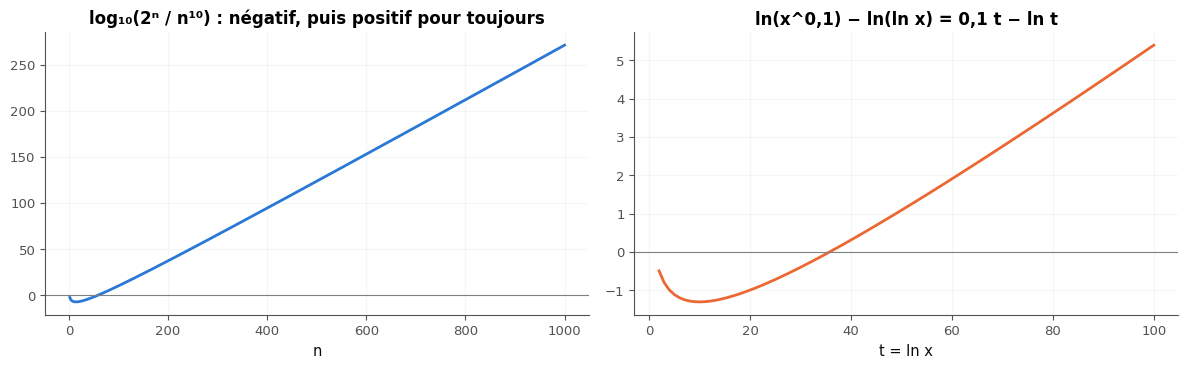

In [32]:
with checked("R6.19 figure"):
    if gap is ... or race is ...:
        print("⏳ Écris d'abord gap et race.")
    else:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        axes[0].plot(n, np.asarray(gap) / math.log(10), color="C0")
        axes[0].axhline(0, color="gray", linewidth=0.8)
        axes[0].set_xlabel("n")
        axes[0].set_title("log₁₀(2ⁿ / n¹⁰) : négatif, puis positif pour toujours")
        axes[1].plot(t, race, color="C1")
        axes[1].axhline(0, color="gray", linewidth=0.8)
        axes[1].set_xlabel("t = ln x")
        axes[1].set_title("ln(x^0,1) − ln(ln x) = 0,1 t − ln t")
        for ax in axes:
            ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

💡 $2^{n}$ passe devant $n^{10}$ pour de bon à $n = 59$, puis l'écart explose : à $n = 1\,000$, $2^{n}$ est $10^{271}$ fois plus grand. $x^{0{,}1}$ ne dépasse $\ln x$ qu'à partir de $\ln x = 36$, soit $x = e^{36} \approx 4 \times 10^{15}$ : « finit par » peut vouloir dire « très loin ».

### Ex R6.20 — Les mêmes données en échelle linéaire et en échelle logarithmique 🎨 ★ ⏱️ 15 min
**Objectif :** tracer les mêmes données sur deux échelles, et lire une croissance exponentielle sur un graphique semi-logarithmique.  
**Prérequis :** fiche §6 ; R0 (matplotlib) · **Parcours :** C, E

Un comptage double à peu près tous les 1,5 pas : `counts` contient $12 \times 1{,}6^{t}$ pour $t = 0$ à 15 (`steps`). Complète `plot_scales(axes, steps, counts)`, qui reçoit **deux axes** côte à côte :
- dans `axes[0]`, les points `(steps, counts)` en échelle ordinaire ;
- dans `axes[1]`, les mêmes points, avec l'axe vertical en échelle logarithmique (`axes[1].set_yscale("log")`, fiche §6) ;
- un titre pour chacun, et des points plutôt qu'une ligne (`"o"`).

La cellule de vérification crée les axes, puis la figure s'affiche. Puis, en lisant le graphique de droite **et** en le justifiant par le calcul :
- a) de combien de décades la droite monte-t-elle à chaque pas ? ($\log_{10} 1{,}6$, 3 décimales)
- b) combien de pas faut-il pour monter d'une décade, c'est-à-dire multiplier le comptage par 10 ? (2 décimales)

Dans ta copie : sur lequel des deux graphiques vois-tu le mieux les premières valeurs ? Et si la croissance ralentissait à la fin, à quoi le verrais-tu sur le graphique de droite ?

In [33]:
steps = np.arange(0, 16)
counts = 12 * 1.6**steps

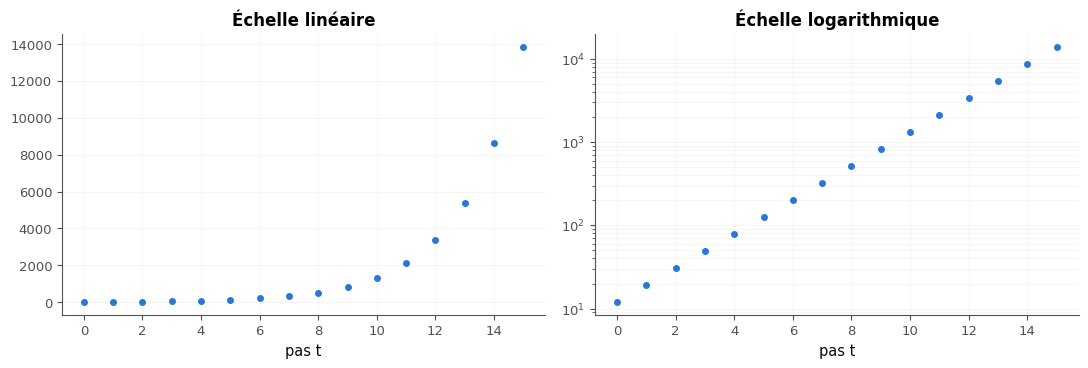

In [34]:
def plot_scales(axes, steps, counts):
    """axes[0]: the points (steps, counts) on a linear scale; axes[1]: the same points with a log y axis. Titles."""
    for ax, scale, title in zip(axes, ("linear", "log"), ("Échelle linéaire", "Échelle logarithmique")):
        ax.plot(steps, counts, "o", markersize=4)
        ax.set_yscale(scale)
        ax.set_title(title)
        ax.set_xlabel("pas t")
        ax.grid(True, which="both" if scale == "log" else "major", alpha=0.3)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_scales(axes, steps, counts)
fig.tight_layout()
plt.show()
answer_R6_20a = round(math.log10(1.6), 3)
answer_R6_20b = round(1 / math.log10(1.6), 2)

In [35]:
wbm.record("R6.20a", math.log10(1.6), decimals=3,
           mistakes={"sur un axe en base 10, la pente est log₁₀ 1,6, pas ln 1,6": math.log(1.6),
                     "la pente en décades par pas est log₁₀ du facteur 1,6, pas le facteur lui-même": 1.6})
wbm.record("R6.20b", 1 / math.log10(1.6), decimals=2,
           mistakes={"une décade divisée par la pente : 1 / log₁₀ 1,6": math.log10(1.6),
                     "1 / log₁₀ 1,6, pas 1 / ln 1,6": 1 / math.log(1.6)})

WBM_ANSWER {"decimals": 3, "hash": "3cfe1b2c37dccf965d53c7a8335f21a67255a12ef7a5b19ad483df9288bb0f59", "hash_coarse": "fb0f713d921d5064dc2a744535fb51ec94fb28f33fa4189f905219464c6849e2", "id": "R6.20a", "kind": "float", "magnitude": -1, "mistakes": {"0ebf729707024fc60cf9505769dab5efd962a087ca06df1e73659776184b43e9": "la pente en décades par pas est log₁₀ du facteur 1,6, pas le facteur lui-même", "41a20198f3533b143997bd098cec45e28af6e905fdd670f0f53a81e22d87dc21": "sur un axe en base 10, la pente est log₁₀ 1,6, pas ln 1,6"}, "sign": 1}
📝 Ex R6.20a : réponse enregistrée (float, 3 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "d4a208b38d2d49dd62ac4f58c00f717f41d7e7bc4f912035140f234d25cec2b1", "hash_coarse": "f2ddd9592cc99bdc640423bba194e882694703b1fc9ec0f2c12f72c4a9d9ed88", "id": "R6.20b", "kind": "float", "magnitude": 0, "mistakes": {"47aadbd2d81fb1ad84517f6dc83c0279286e143d4a11a5c801d994cf04ab4c99": "une décade divisée par la pente : 1 / log₁₀ 1,6", "9f42da6e303b8670d5fcc90f26828f459b2

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [36]:
with checked("R6.20 vérifications"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    try:
        created = drawn(plot_scales, axes, steps, counts)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    problems = []
    if created:
        problems.append("ta fonction ouvre sa propre figure : dessine dans les axes reçus (axes[0].plot, …)")
    else:
        for k, ax in enumerate(axes):
            ys = []
            for line in ax.lines:
                ys += list(np.asarray(line.get_ydata(), dtype=float))
            for collection in ax.collections:
                ys += list(np.asarray(collection.get_offsets(), dtype=float)[:, 1])
            if not any(np.isclose(y, counts[-1]) for y in ys):
                problems.append(f"rien n'est tracé dans axes[{k}] (dessine les données avec axes[{k}].plot(...), pas "
                                f"plt.plot)")
        if axes[0].get_yscale() != "linear":
            problems.append("axes[0] doit garder l'échelle linéaire")
        if axes[1].get_yscale() != "log":
            problems.append("l'axe vertical de axes[1] en échelle logarithmique (axes[1].set_yscale(\"log\"))")
        if not all(ax.get_title() for ax in axes):
            problems.append("un titre pour chaque graphique (ax.set_title)")
    if problems:
        print("❌ Ex R6.20 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R6.20 : deux graphiques, l'un en échelle linéaire, l'autre en échelle logarithmique.")

✅ Ex R6.20 : deux graphiques, l'un en échelle linéaire, l'autre en échelle logarithmique.


💡 Sur le graphique de droite, les points sont alignés : la pente vaut $\log_{10} 1{,}6 \approx 0{,}204$ décade par pas, soit une décade tous les 4,9 pas environ ($1{,}6^{4{,}9} \approx 10$). Un ralentissement à la fin se verrait comme des points qui passent sous la droite.

## Partie C · Erreurs de règles et documentation

Fiche §2 à §4. Trois règles mal appliquées à trouver, puis la documentation des logarithmes de NumPy.

### Ex R6.21 — Chasse à l'erreur : ln(a + b), e^(a + b) et log(0) 🐛 ★★ ⏱️ 15 min
**Objectif :** repérer les règles de exp et de ln mal appliquées dans du code, et ce que donne le logarithme de 0.  
**Prérequis :** fiche §2 et §3 · **Parcours :** C, E

Trois petites fonctions utilisent exp et ln. Certaines lignes sont fausses. **Sans rien exécuter d'abord**, trouve-les.

```python
def total_log_prob(probabilities):
    """ln of the product of independent probabilities, computed as a sum of logarithms."""
    total = 1                                                     # (A)
    for p in probabilities:                                       # (B)
        total = total + math.log(p)                               # (C)
    return total                                                  # (D)


def log_of_sum(a, b):
    """ln(a + b), for a > 0 and b > 0."""
    return math.log(a) + math.log(b)                              # (E)


def grow(start, rate, t1, t2):
    """start × e^(rate × t1), then that value × e^(rate × t2): the value after t1 + t2 of continuous growth."""
    return start * (math.exp(rate * t1) + math.exp(rate * t2))    # (F)
```

- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) même une fois corrigée, `total_log_prob([0.5, 0.0])` ne rend pas de nombre : quel est le nom de l'erreur levée ? (`math.log` de 0 ; fiche §3)

Puis corrige les trois fonctions dans la cellule ci-dessous (elle contient le code fautif) : la vérification calcule c), la liste `[total_log_prob([0.5, 0.4]), log_of_sum(2, 3), grow(100, 0.05, 4, 6)]`.

Dans ta copie : une probabilité nulle dans un produit le rend nul. Que devient sa log-probabilité, et pourquoi un modèle qui donne la probabilité 0 à ce qui arrive vraiment est-il infiniment mauvais ?

In [37]:
answer_R6_21a = "AEF"
answer_R6_21b = raised(lambda: sum(math.log(p) for p in [0.5, 0.0]))

def total_log_prob(probabilities):
    """ln of the product of independent probabilities, computed as a sum of logarithms."""
    total = 0                                                     # (A) corrected: a sum starts at 0
    for p in probabilities:                                       # (B)
        total = total + math.log(p)                               # (C)
    return total                                                  # (D)


def log_of_sum(a, b):
    """ln(a + b), for a > 0 and b > 0."""
    return math.log(a + b)                                        # (E) corrected: ln(a + b) does not split


def grow(start, rate, t1, t2):
    """start × e^(rate × t1), then that value × e^(rate × t2): the value after t1 + t2 of continuous growth."""
    return start * math.exp(rate * t1) * math.exp(rate * t2)      # (F) corrected: a product of exponentials


print(answer_R6_21a, answer_R6_21b, [total_log_prob([0.5, 0.4]), log_of_sum(2, 3), grow(100, 0.05, 4, 6)])

AEF ValueError [-1.6094379124341003, 1.6094379124341003, 164.87212707001282]


In [38]:
wbm.record("R6.21a", "AEF",
           mistakes={"il manque une ligne fautive : calcule total_log_prob([1.0]) à la main : ln 1 = 0, que doit rendre la fonction ?": "EF",
                     "il manque une ligne fautive : essaie a = b = 1 : que vaut ln(1 + 1), et que rend la ligne ?": "AF",
                     "il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …": "AE",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABEF",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "ACEF",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "ADEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : calcule total_log_prob([1.0]) à la main : ln 1 = 0, que doit rendre la fonction ?": "BEF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : calcule total_log_prob([1.0]) à la main : ln 1 = 0, que doit rendre la fonction ?": "CEF",
                     "la ligne (D) est correcte, et il manque une ligne fautive : calcule total_log_prob([1.0]) à la main : ln 1 = 0, que doit rendre la fonction ?": "DEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : essaie a = b = 1 : que vaut ln(1 + 1), et que rend la ligne ?": "ABF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : essaie a = b = 1 : que vaut ln(1 + 1), et que rend la ligne ?": "ACF",
                     "la ligne (D) est correcte, et il manque une ligne fautive : essaie a = b = 1 : que vaut ln(1 + 1), et que rend la ligne ?": "ADF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …": "ABE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …": "ACE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …": "ADE",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "E", "F"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "C", "D", "AB", "AC", "AD", "BC", "BD", "BE", "BF", "CD", "CE", "CF", "DE", "DF", "ABC", "ABD", "ACD", "BCD", "BCE", "BCF", "BDE", "BDF", "CDE", "CDF", "ABCD", "ABCE", "ABCF", "ABDE", "ABDF", "ACDE", "ACDF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDE", "ABCDF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCEF", "ABDEF", "ACDEF", "ABCDEF"}})
wbm.record("R6.21b", "ValueError",
           mistakes={"math.log(0) ne renvoie pas -inf (c'est NumPy qui le fait) : il lève une erreur ; lis son nom":
                         {"aucune", "-inf", "nan"},
                     "le nom exact de l'erreur que lève math.log(0) : exécute-le pour le voir":
                         {"ZeroDivisionError", "OverflowError", "MathError", "ArithmeticError"}})
wbm.record("R6.21c", [math.log(0.2), math.log(5), 100 * math.exp(0.5)], decimals=4,
           mistakes={"total_log_prob : une somme de logarithmes part de 0": [1 + math.log(0.2), math.log(5),
                                                                             100 * math.exp(0.5)],
                     "log_of_sum : ln(a + b) se calcule tel quel, il ne se découpe pas": [math.log(0.2), math.log(6),
                                                                                          100 * math.exp(0.5)],
                     "grow : e^(u + v) = e^u × e^v, un produit": [math.log(0.2), math.log(5),
                                                                 100 * (math.exp(0.2) + math.exp(0.3))]})

WBM_ANSWER {"hash": "4255b7111931fd8187c18649e71a28ff23141e37dda47f247230e0cc288bd9fe", "id": "R6.21a", "kind": "str", "mistakes": {"02c414923b48e260f69009fde7869cd6944604f225425c341b71392d66b4178a": "la ligne (D) est correcte, et il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …", "06eed50feb85375737894c6d9d8c894996180a36c6964de698aab53ff9cbb055": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "07b55e94387f813f2a088d58a6a0b31dca37401cc9c1a316a32961a8f381c174": "la ligne (C) est correcte, et il manque une ligne fautive : e^(u + v) est un produit d'exponentielles : relis la règle e^(u + v) = …", "09466bcbe563409987d00a978991a4235c551c1a8ab03d79d3d1195e612607f3": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0d102d22bb0c975cb16a9be418697688e9e10793d1e8a6c5e85b66a1e935f77a": "plusieurs l

💡 (A) une somme part de 0, pas de 1 (c'est un produit qui part de 1). (E) $\ln(a + b)$ ne se découpe pas : c'est $\ln(ab)$ qui vaut $\ln a + \ln b$. (F) $e^{u + v} = e^{u} \times e^{v}$, un produit. Et `math.log(0)` lève `ValueError` (*math domain error*) : la log-probabilité d'un événement impossible vaut $-\infty$, et NumPy la renvoie telle quelle (`-inf`).

### Ex R6.22 — Lire la documentation de `numpy.log`, `log2`, `log10`, `log1p` 🛠️ ★ ⏱️ 15 min
**Objectif :** lire la documentation d'une fonction de NumPy pour savoir ce qu'elle calcule, sur quelles entrées, et pourquoi une variante existe.  
**Prérequis :** fiche §3 et §4 · **Parcours :** C

Une documentation dit ce qu'une fonction calcule, ce qu'elle rend pour les entrées interdites et à quoi servent ses variantes. Lis celle de `np.log1p` (la cellule en affiche le début ; `help(np.log1p)` ou la [page en ligne](https://numpy.org/doc/stable/reference/generated/numpy.log1p.html) donnent tout), puis celles de `np.log`, `np.log2` et `np.log10`. Complète la cellule avec tes expériences.

Dans ta copie :
1. Que calcule `np.log1p(x)` ? Pour quels $x$ est-il plus précis que `np.log(1 + x)`, et pourquoi (pense à ce que devient `1 + 1e-12` en flottant, R1) ?
2. Que rendent `np.log(0.0)` et `np.log(-1.0)` ? Et `math.log` dans les mêmes cas (R6.21) ? Lequel des deux comportements préfères-tu pour détecter une erreur, et lequel pour calculer sur tout un tableau ?
3. Quelle fonction de NumPy calcule $\log_{2}$, laquelle $\log_{10}$, et laquelle $\ln$ ? Et `np.log` accepte-t-il une base en second argument, comme `math.log` ?

In [39]:
# 1. The first lines of the documentation of np.log1p (np.info shows the full text; or help(np.log1p))
print(np.log1p.__doc__[:700])

# 2. Your experiments: np.log(1 + 1e-12) against np.log1p(1e-12); np.log2(8.0) and np.log10(0.001);
#    np.log(0.0) and np.log(-1.0) (inside `with np.errstate(all="ignore"):` to silence the alerts)
print("np.log(1 + 1e-12) =", np.log(1 + 1e-12), "  np.log1p(1e-12) =", np.log1p(1e-12))
print("np.log2(8.0) =", np.log2(8.0), "  np.log10(0.001) =", np.log10(0.001))
with np.errstate(all="ignore"):
    print("np.log(0.0) =", np.log(0.0), "  np.log(-1.0) =", np.log(-1.0))

log1p(x, /, out=None, *, where=True, casting='same_kind', order='K', dtype=None, subok=True[, signature])

Return the natural logarithm of one plus the input array, element-wise.

Calculates ``log(1 + x)``.

Parameters
----------
x : array_like
    Input values.
out : ndarray, None, or tuple of ndarray and None, optional
    A location into which the result is stored. If provided, it must have
    a shape that the inputs broadcast to. If not provided or None,
    a freshly-allocated array is returned. A tuple (possible only as a
    keyword argument) must have length equal to the number of outputs.
where : array_like, optional
    This condition is broadcast over the input. At locations wher
np.log(1 + 1e-12) = 1.000088900581841e-12   np.log1p(1e-12) = 9.999999999995e-13
np.log2(8.0) = 3.0   np.log10(0.001) = -3.0
np.log(0.0) = -inf   np.log(-1.0) = nan


💡 `np.log1p(x)` calcule $\ln(1 + x)$ sans former `1 + x`, qui perd presque tous les chiffres de `x` quand `x` est minuscule : `np.log(1 + 1e-12)` est faux dès le cinquième chiffre, `np.log1p(1e-12)` est exact. `np.log(0.0)` rend `-inf` et `np.log(-1.0)` rend `nan`, avec une alerte : pratique sur un tableau, mais à surveiller. `np.log` n'a pas d'argument de base : c'est le second argument de `math.log` seul qui en a un.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Simplifies-tu une expression avec exp et ln, et résous-tu $e^{x} = c$, $a^{n} > c$ en surveillant le domaine et le sens des inégalités ?
2. Passes-tu d'une base de logarithme à une autre, et comptes-tu en bits et en nats ?
3. Sais-tu comparer des croissances, lire une échelle logarithmique, et passer d'une probabilité à sa cote et à son logit ?

**La suite** : R7, *Limites et dérivation*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.